# Face Detection Using OpenCV
A beginner-friendly notebook demonstrating face detection with a pre-trained Haar Cascade classifier.

**What you'll learn:** load an image, convert it to grayscale, detect faces, draw bounding boxes, and optionally run detection with a webcam.

## 1. Install OpenCV
Run this cell if OpenCV is not already installed.

In [9]:
%pip install "opencv-python<5" matplotlib

# Note: After running this install, please go to 'Runtime' -> 'Restart session'
# in the Google Colab menu so Python loads the downgraded version correctly.

## 2. Import libraries

In [10]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

print('OpenCV version:', cv2.__version__)

OpenCV version: 4.14.0


## 3. Load the pre-trained Haar Cascade model
OpenCV includes a frontal-face Haar Cascade XML file. This model detects frontal faces; it does not identify who a person is.

In [11]:
import cv2

cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'

# Instantiate the CascadeClassifier using cv2
face_cascade = cv2.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise RuntimeError('Could not load Haar Cascade classifier.')

print('Haar Cascade model loaded successfully.')

Haar Cascade model loaded successfully.


## 4. Load an image


In [12]:
image_path = '/usr/src/boys img.jpg'  # Change this to your image filename
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(
        f"Could not read '{image_path}'. Put the image in the notebook folder "
        "or update image_path to the correct location."
    )

print('Image shape (height, width, channels):', image.shape)

Image shape (height, width, channels): (651, 976, 3)


## 5. Convert the image to grayscale
Haar Cascade detection is commonly performed on grayscale images.

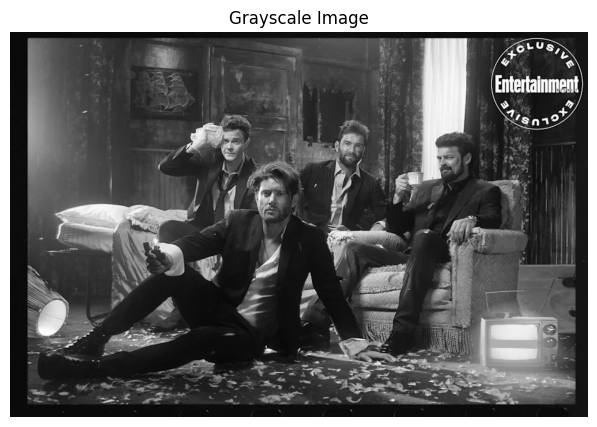

In [13]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 5))
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off');

## 6. Detect faces
- `scaleFactor=1.1`: image pyramid scale step.
- `minNeighbors=5`: how many nearby detections are needed to retain a candidate.
- `minSize=(30, 30)`: ignore detections smaller than this size.

In [14]:
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print(f'Number of faces detected: {len(faces)}')
print('Face boxes (x, y, width, height):')
for box in faces:
    print(tuple(int(v) for v in box))

Number of faces detected: 4
Face boxes (x, y, width, height):
(710, 194, 47, 47)
(346, 164, 54, 54)
(552, 170, 52, 52)
(410, 248, 66, 66)


## 7. Draw bounding boxes around detected faces
The coordinates `(x, y)` mark the top-left corner; `width` and `height` determine the rectangle size.

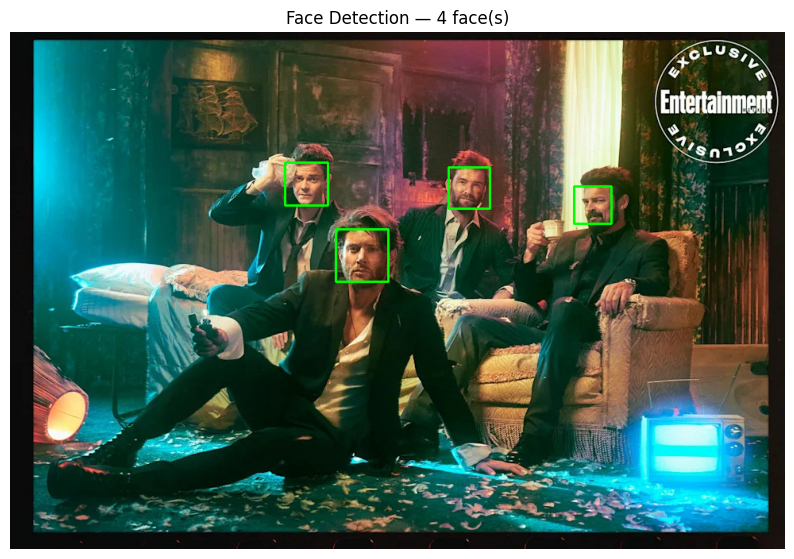

In [15]:
output = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)

output_rgb = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 7))
plt.imshow(output_rgb)
plt.title(f'Face Detection — {len(faces)} face(s)')
plt.axis('off');

## 8. Save the output image

In [16]:
output_path = 'face_detection_output.jpg'
if not cv2.imwrite(output_path, output):
    raise IOError(f'Could not save output to {output_path}')
print('Saved detected image to:', output_path)

Saved detected image to: face_detection_output.jpg
